# Day 2 · 03 — Lab: exogenous variables and responsiveness (30 min)

A forecast that is accurate but **does not respond to price and promotion** is useless for planning. This lab

1. adds price and promotion as **future covariates** (and hierarchy ids as static covariates) to NHITS;
2. checks accuracy, overall and on series **with a promotion inside the test window**;
3. runs **response-curve checks**: shift the planned price by −25 % … +25 % and switch promotions on and off,
   then ask whether the model reacts in the right direction and by a plausible amount;
4. compares with LightGBM, where we can *force* the right sign with a monotone constraint.

In [1]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

import bootcamp as bc

warnings.filterwarnings("ignore")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)
palette = ["#000000", "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00"]
plt.rcParams.update({"figure.figsize": (12, 5), "axes.prop_cycle": plt.cycler(color=palette)})

INPUT_SIZE = 4 * bc.H      # use the lookback you found in Lab 02

/home/user/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MAE
from neuralforecast.models import NHITS

panel = bc.load_panel()
train, test = bc.split(panel)
X = bc.FUTR_EXOG_COLS          # promo, discount_depth, price_index
Y_train = bc.to_nixtla(train, X)
futr = bc.to_nixtla(test, X + ["price_ratio_to_rolling_mean"]).drop(columns="y")   # ratio is used by the scenarios
static = bc.static_frame(train)
print("future covariates:", X, "| static:", bc.STATIC_COLS)

2026-10-27 21:52:37,377	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-10-27 21:52:37,859	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


future covariates: ['promo', 'discount_depth', 'price_index'] | static: ['log_mean_sales', 'share_zero_weeks', 'share_promo_weeks']


## Intuition: accuracy vs responsiveness

![What a response curve should look like](slides/img/response_sketch.png)

* **Accuracy** asks: did you predict what happened?
* **Responsiveness** asks: if we changed the price, would you predict the right thing?

A model can score well and still answer "what if?" wrongly, because it may have learned **when** promotions
happen rather than **what they do**. Retailers discount when they expect demand to be high, so the data alone
can even suggest "cheaper → fewer sales" (ice-cream sales and sunburn rise together; banning ice cream does not
prevent sunburn).

Covariates must be **relative** (price index, discount depth): a raw price of 0.99 vs 39.99 tells a global
model "cheap item" or "expensive item", not "cheaper than usual".

## 1. NHITS without and with covariates

Two lessons that cost us an afternoon, so you do not have to repeat them:

* **Covariates must be scale-free.** Raw `sale_price` ranges from cents to tens of euros across items. Fed to
  a global network it made NHITS *worse* than no covariates at all (mean RMSSE roughly doubled in our runs).
  `price_index` (price / the series' median training price) and `discount_depth` carry the same information
  on a common scale.
* **The scaler touches the covariates too.** With `scaler_type="robust"` a promo flag that is 0 in most weeks
  has an IQR of 0, and the scaled flag explodes. `"standard"` behaves.

In [3]:
common = dict(h=bc.H, input_size=INPUT_SIZE, loss=MAE(), scaler_type="standard", max_steps=bc.MAX_STEPS,
              random_seed=bc.RANDOM_SEED, **bc.trainer_kwargs())

nf_plain = NeuralForecast(models=[NHITS(alias="NHITS_noexog", **common)], freq=bc.FREQ)
with bc.Timer() as t_plain:
    nf_plain.fit(df=Y_train[["unique_id", "ds", "y"]], val_size=bc.H)

nf_x = NeuralForecast(models=[NHITS(alias="NHITSx", futr_exog_list=X, stat_exog_list=bc.STATIC_COLS, **common)],
                      freq=bc.FREQ)
with bc.Timer() as t_x:
    nf_x.fit(df=Y_train, static_df=static, val_size=bc.H)

fcst = nf_plain.predict().merge(nf_x.predict(futr_df=futr[["unique_id", "ds"] + X], static_df=static), on=["unique_id", "ds"])

## 2. LightGBM with the same covariates, with and without a monotone price constraint

In [4]:
import lightgbm as lgb
from mlforecast import MLForecast
from mlforecast.lag_transforms import RollingMean
from mlforecast.target_transforms import LocalStandardScaler

feature_order = X  # mlforecast puts exogenous columns first, then lags, lag transforms and date features
lag_feats = ["lag1", "lag2", "lag4", "lag13", "lag52", "rolling_mean_lag1_window_size4",
             "rolling_mean_lag1_window_size13", "month", "week"]
# price ↓ → sales ↑ ; promo ↑ → sales ↑ ; discount ↑ → sales ↑
mono = {"price_index": -1, "promo": 1, "discount_depth": 1}
constraints = [mono.get(c, 0) for c in X] + [0] * len(lag_feats)

def make_mlf(**lgb_kw):
    return MLForecast(
        models={k: lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=63, verbosity=-1,
                                     random_state=bc.RANDOM_SEED, **v) for k, v in lgb_kw.items()},
        freq=bc.FREQ, lags=[1, 2, 4, 13, 52], lag_transforms={1: [RollingMean(4), RollingMean(13)]},
        date_features=["month", "week"], target_transforms=[LocalStandardScaler()],
    )

mlf = make_mlf(LightGBMx={}, LightGBMx_mono={"monotone_constraints": constraints, "monotone_constraints_method": "advanced"})
with bc.Timer() as t_lgb:
    mlf.fit(Y_train, static_features=[])
assert list(mlf.ts.features_order_) == X + lag_feats, mlf.ts.features_order_
fcst = fcst.merge(mlf.predict(h=bc.H, X_df=futr[["unique_id", "ds"] + X]), on=["unique_id", "ds"])

In [5]:
bc.save_forecasts(fcst, "03_exogenous")
bc.record(fcst, test, train, lab="03 exogenous",
          fit_seconds={"NHITS_noexog": t_plain.seconds, "NHITSx": t_x.seconds,
                       "LightGBMx": t_lgb.seconds / 2, "LightGBMx_mono": t_lgb.seconds / 2})

,model,mean_rmsse,median_rmsse,mean_mase,mean_smape,n_series,wape,lab,fit_seconds,notes,recorded_at
0,NHITSx,1.132742,0.601978,2.669862,0.271909,1999,0.297665,03 exogenous,33.792775,,2026-10-27 21:53:48
1,NHITS_noexog,1.148003,0.630746,2.587417,0.265112,1999,0.349973,03 exogenous,31.592917,,2026-10-27 21:53:48
2,LightGBMx,1.202907,0.630557,2.986261,0.284839,1999,0.342139,03 exogenous,1.510798,,2026-10-27 21:53:48
3,LightGBMx_mono,1.203780,0.629027,3.006977,0.286918,1999,0.339957,03 exogenous,1.510798,,2026-10-27 21:53:48


### Where do covariates help? Split by "promotion inside the test window"

In [6]:
models = ["NHITS_noexog", "NHITSx", "LightGBMx", "LightGBMx_mono"]
promo_ids = test.group_by("unique_id").agg((pl.col("promo") > 0).any().alias("promo_in_test"))
m = bc.score(fcst, test, train, models)
m = m[m.metric == "rmsse"].merge(promo_ids.to_pandas(), on="unique_id")
m.groupby("promo_in_test")[models].mean().round(3)

,NHITS_noexog,NHITSx,LightGBMx,LightGBMx_mono
promo_in_test,,,,
False,0.908,0.953,1.031,1.035
True,1.294,1.242,1.307,1.306


### Reading the result

Covariates help **where they carry information**. In the reference run, on items with a promotion in the test
window, NHITS improved from ≈ 1.29 to ≈ 1.24; on items without one it got slightly worse (≈ 0.91 → 0.95),
because there the extra inputs are mostly noise to fit.

*Reference run: 2,000 series, laptop CPU, 500 steps. Your numbers will differ a little; the reading should not.*

## 3. Response-curve checks

Keep everything fixed and change one planned input in the test window:

* **price**: multiply the planned price by 0.75 … 1.25 and recompute the derived price features;
* **promotion**: set `promo` to 0 or 1 for every test week.

A sane model has a **downward-sloping price curve** and a **positive promo lift**. We measure arc elasticity
`%Δ forecast / %Δ price` per series, as in `nbeats_weekly_phase3.py`.

In [7]:
MULTS = [0.75, 0.85, 0.95, 1.0, 1.05, 1.15, 1.25]

def scenario(df: pd.DataFrame, mult: float | None = None, promo: float | None = None) -> pd.DataFrame:
    out = df.copy()
    if mult is not None:
        out["price_index"] = out["price_index"] * mult
        out["discount_depth"] = np.maximum(0, 1 - out["price_ratio_to_rolling_mean"] * mult)
    if promo is not None:
        out["promo"] = promo
    return out

def predict_all(futr_s: pd.DataFrame) -> pd.DataFrame:
    p = nf_x.predict(futr_df=futr_s[["unique_id", "ds"] + X], static_df=static)
    p = p.merge(mlf.predict(h=bc.H, X_df=futr_s[["unique_id", "ds"] + X]), on=["unique_id", "ds"])
    return p.groupby("unique_id")[["NHITSx", "LightGBMx", "LightGBMx_mono"]].sum()

curves = {mult: predict_all(scenario(futr, mult=mult)) for mult in MULTS}
base = curves[1.0]

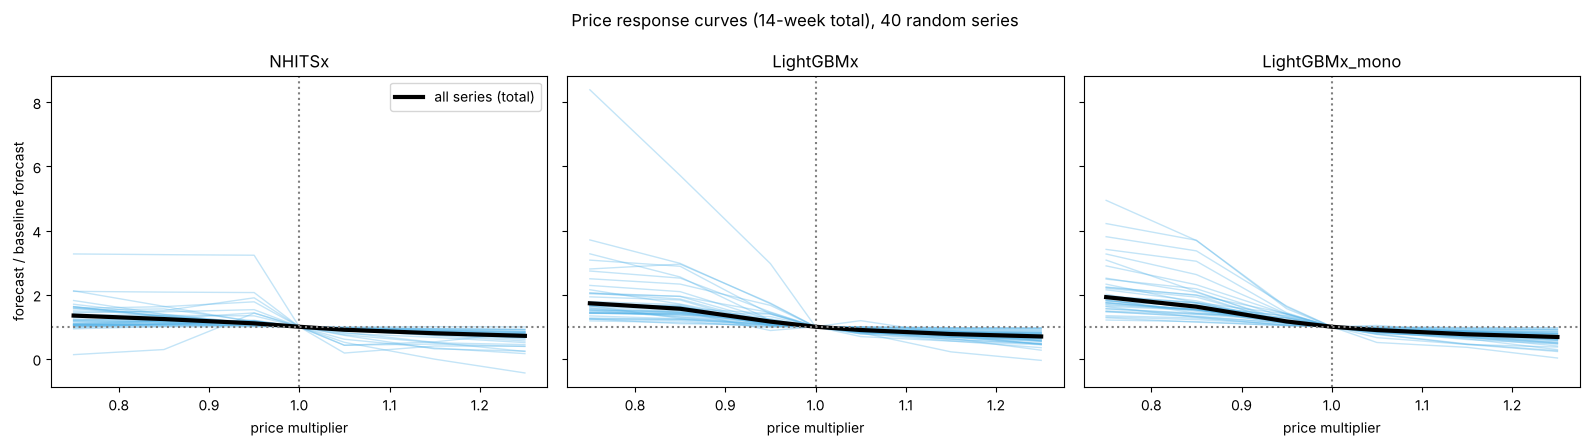

In [8]:
resp_models = ["NHITSx", "LightGBMx", "LightGBMx_mono"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
total = pd.DataFrame({mult: c.sum() / base.sum() for mult, c in curves.items()}).T
for ax, model in zip(axes, resp_models):
    rel = pd.DataFrame({mult: c[model] / base[model].replace(0, np.nan) for mult, c in curves.items()})
    for uid in rel.dropna().sample(min(40, len(rel.dropna())), random_state=1).index:
        ax.plot(MULTS, rel.loc[uid], color=palette[5], alpha=0.35, lw=1)
    ax.plot(MULTS, total[model], color="black", lw=3, label="all series (total)")
    ax.axhline(1, color="grey", ls=":"), ax.axvline(1, color="grey", ls=":")
    ax.set_title(model), ax.set_xlabel("price multiplier")
axes[0].set_ylabel("forecast / baseline forecast")
axes[0].legend()
plt.suptitle("Price response curves (14-week total), 40 random series")
plt.tight_layout()

In [9]:
def response_report(model: str) -> dict:
    lo, hi = curves[0.75][model], curves[1.25][model]
    b = base[model].replace(0, np.nan)
    elasticity = ((hi - lo) / b) / 0.5
    stacked = np.stack([curves[x][model].values for x in MULTS])
    monotone = (np.diff(stacked, axis=0) <= 1e-6).all(axis=0)
    return {
        "model": model,
        "median_elasticity": float(np.nanmedian(elasticity)),
        "share_perverse (>0)": float(np.nanmean(elasticity > 0.05)),
        "share_flat (|e|<0.05)": float(np.nanmean(elasticity.abs() < 0.05)),
        "share_monotone_decreasing": float(monotone.mean()),
    }

promo_on, promo_off = predict_all(scenario(futr, promo=1.0)), predict_all(scenario(futr, promo=0.0))
report = pd.DataFrame([response_report(m) for m in resp_models]).set_index("model")
report["median_promo_lift"] = [(promo_on[m] / promo_off[m].replace(0, np.nan) - 1).median() for m in resp_models]
report.round(3)

,median_elasticity,share_perverse (>0),share_flat (|e|<0.05),share_monotone_decreasing,median_promo_lift
model,,,,,
NHITSx,-1.121,0.018,0.010,0.398,0.280
LightGBMx,-2.219,0.006,0.001,0.734,0.089
LightGBMx_mono,-2.748,0.004,0.000,0.978,0.101


### Is the size plausible? Compare with what the data says

A crude empirical check: per series, log-sales lift in promo weeks vs non-promo weeks in **training**. If the
model's promo lift is far from this, it has either ignored the flag or memorised a few extreme events.

In [10]:
emp = (train.filter(pl.col("y") > 0)
       .group_by("unique_id", "promo").agg(pl.col("y").log().mean().alias("ly"))
       .pivot(on="promo", index="unique_id", values="ly").drop_nulls())
emp_lift = np.exp(emp["1.0"] - emp["0.0"]) - 1
print(f"empirical median promo lift (train weeks): {np.median(emp_lift):.2f}  "
      f"vs model lifts: {report['median_promo_lift'].round(2).to_dict()}")

empirical median promo lift (train weeks): 0.72  vs model lifts: {'NHITSx': 0.28, 'LightGBMx': 0.09, 'LightGBMx_mono': 0.1}


### Reading the result

![Lab 03 results](slides/img/res_lab03.png)

* **Direction mostly right**: fewer than 2 % of the price curves point the wrong way, and the monotone
  constraint makes 98 % of LightGBM's curves slope down everywhere (vs 73 % without it, 40 % for NHITSx).
* **Size wrong**: the data shows a **+72 %** median promo lift; the models predict **+9 % to +28 %**. A global
  model pulls every item toward the average week, so its reactions are timid.
* The best-scoring model in this lab under-predicts what a promotion does by a factor of about 2.5. Check lifts
  against the data before anyone plans a promotion with them.

*Reference run: 2,000 series, laptop CPU, 500 steps. Your numbers will differ a little; the reading should not.*

## Discussion

* The covariates may barely move **mean RMSSE** yet change the **promo-week** errors a lot. Which number
  would a category manager care about?
* An unconstrained model can learn **perverse** elasticities (price up → sales up) from confounding: prices
  are cut when demand is expected to be high. Monotone constraints fix the sign, not the confounding.
* A neural net has no monotone switch. Options: constrain the architecture, add a penalty, or post-check the
  response curve and fall back to a simpler model for series that fail it.